# MLP external experiments for the shared study

**Huang Tianfeng and Yang Yifei**

This notebook documents the MLP decisions behind the [shared six-model study](../Improving%20Rare%20Postural%20Transitions.ipynb). It follows the same six-stage structure as the [LDA companion](LDA%20external.ipynb): controlled changes, longer context, practical selection, PCA, and a fixed test comparison. The earlier [MLP tuning](../../Previous%20Attempts/24_10_2026_TianFeng/nn_tuning.ipynb) and [selected three-window model](../../Previous%20Attempts/24_10_2026_TianFeng/nn_model.ipynb) are historical sources; this notebook also includes the later eleven-window study used in the shared final comparison.

Sections 1–5 use participant-grouped validation on the 21 training participants. Section 6 reports the already inspected nine-participant test split descriptively. The main metric is macro-F1 across transitions 7–12; common-class macro-F1, all-class macro-F1, accuracy, recall, and elapsed time provide context. The MLP uses 256–128–64 hidden units, batch normalisation, dropout, Adam, and the fixed eight-window posture-memory rule. For the matched six-model comparisons, training lasts 15 epochs, including the single-window baseline. That baseline has no class weighting or oversampling, but it does include memory.

Recorded results appear without fitting models. Set `RUN_MLP_EXPERIMENTS`, `RUN_MLP_TUNING`, `RUN_MLP_PCA`, or `RUN_MLP_TEST` to `True` to rerun the corresponding stage. The early stopping study uses a different training protocol from the later fixed-15-epoch comparisons; its F1 values should not be pooled with them. This notebook needs only the project CSVs and imported packages, and does not import another notebook.

In [1]:
import os
for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[key] = "2"
from pathlib import Path
from time import perf_counter
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch
from IPython.display import display
from threadpoolctl import threadpool_limits
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler

THREAD_LIMITS = threadpool_limits(limits=2)
RUN_MLP_EXPERIMENTS = False
RUN_MLP_TUNING = False
RUN_MLP_PCA = False
RUN_MLP_TEST = False
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "our approach/wrangled data/hapt_train.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the repository root or a folder inside it.")
train_df = pd.read_csv(ROOT / "our approach/wrangled data/hapt_train.csv")
META_COLUMNS = ["subject_id", "activity_id", "activity_label"]
FEATURE_COLUMNS = [c for c in train_df.columns if c not in META_COLUMNS]
LABELS = np.arange(1, 13)
TRANSITION_LABELS = np.arange(7, 13)
assert len(FEATURE_COLUMNS) == 561
print("Recorded results mode; optional fits:", {"ablation/context": RUN_MLP_EXPERIMENTS,
      "early tuning": RUN_MLP_TUNING, "PCA": RUN_MLP_PCA, "test": RUN_MLP_TEST})
print("Current environment:", platform.python_version(), "NumPy", np.__version__,
      "pandas", pd.__version__, "scikit-learn", sklearn.__version__, "PyTorch", torch.__version__)

Recorded results mode; optional fits: {'ablation/context': False, 'early tuning': False, 'PCA': False, 'test': False}
Current environment: 3.10.6 NumPy 1.26.4 pandas 2.3.3 scikit-learn 1.7.2 PyTorch 2.10.0


## Shared data, context and evaluation rules

Each row has 561 sensor features; participant and activity columns are metadata. Neighbouring features are clipped at participant boundaries. The prepared CSV does not identify every recording boundary within a participant. Symmetric context includes future rows and therefore describes an offline or delayed method. Scaling and PCA fit only on training-fold data. Class weights come from the original training-fold labels; when oversampling is used, copied rows inherit those weights.

The model and memory functions below match the shared notebook. Memory only changes SIT_TO_LIE versus STAND_TO_LIE predictions using preceding prediction probabilities, without true validation or test labels. It stays on for the fixed-epoch comparisons in Sections 1–6.

In [2]:
def arrays(frame):
    x = frame[FEATURE_COLUMNS].to_numpy(dtype=np.float32)
    y = frame.activity_id.to_numpy(dtype=np.int64)
    groups = frame.subject_id.to_numpy(dtype=np.int64)
    return x, y, groups

def add_context(x, groups, mode="single"):
    if mode == "single":
        offsets = (0,)
    elif mode == "previous":
        offsets = (-1, 0)
    elif mode == "bidirectional":
        offsets = (-1, 0, 1)
    elif isinstance(mode, int) and mode > 0 and mode % 2 == 1:
        offsets = tuple(range(-(mode // 2), mode // 2 + 1))
    else:
        raise ValueError(f"Unknown context: {mode}")
    starts = np.r_[0, np.flatnonzero(groups[1:] != groups[:-1]) + 1]
    ends = np.r_[starts[1:] - 1, len(groups) - 1]
    first = np.repeat(starts, ends - starts + 1)
    last = np.repeat(ends, ends - starts + 1)
    row = np.arange(len(x))
    return np.hstack([x[np.clip(row + offset, first, last)] for offset in offsets])

def class_weights(y, exponent=0.5):
    counts = np.bincount(y, minlength=13)
    sample_weight = counts[y].astype(float) ** (-exponent)
    return sample_weight / sample_weight.mean()

def oversample_indices(y, target, seed=42):
    rng = np.random.default_rng(seed)
    indices = [np.arange(len(y))]
    for label in TRANSITION_LABELS:
        found = np.flatnonzero(y == label)
        if len(found) < target:
            indices.append(rng.choice(found, size=target - len(found), replace=True))
    return np.concatenate(indices)

def scores(y_true, y_pred):
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=LABELS, zero_division=0
    )
    return {
        "transition_f1": float(f1[6:].mean()),
        "transition_recall": float(recall[6:].mean()),
        "common_f1": float(f1[:6].mean()),
        "macro_f1": float(f1.mean()),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "per_class_f1": f1,
        "per_class_recall": recall,
        "per_class_precision": precision,
        "support": support,
    }

x_train, y_train, groups_train = arrays(train_df)
assert x_train.shape == (7767, 561)
assert len(np.unique(groups_train)) == 21
assert len(np.unique(groups_train)) == 1 + np.count_nonzero(groups_train[1:] != groups_train[:-1])
SPLITS = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42).split(
    x_train, y_train, groups_train))
for tr, va in SPLITS:
    assert set(groups_train[tr]).isdisjoint(groups_train[va])
np.testing.assert_array_equal(np.sort(np.concatenate([va for _, va in SPLITS])),
                              np.arange(len(y_train)))
display(pd.DataFrame({"fold": range(1, 4),
                      "training_participants": [sorted(set(groups_train[tr])) for tr, _ in SPLITS],
                      "validation_participants": [sorted(set(groups_train[va])) for _, va in SPLITS]}))

,fold,training_participants,validation_participants
0,1,"[1, 5, 6, 11, 14, 15, 16, 17, 19, 21, 22, 23, ...","[3, 7, 8, 25, 26, 27, 29]"
1,2,"[3, 6, 7, 8, 11, 14, 15, 16, 23, 25, 26, 27, 2...","[1, 5, 17, 19, 21, 22, 30]"
2,3,"[1, 3, 5, 7, 8, 17, 19, 21, 22, 25, 26, 27, 29...","[6, 11, 14, 15, 16, 23, 28]"


In [3]:
RECORDED_TRAIN_HASHES = {
    "features": "0c9ad2df3942cbb6e0f4d44e2b6f12ac64a7fa02fd5ee5b69d8185479b69a32b",
    "labels": "638a27667b3423d4f33d86b827905e65c4319cbaa209e19354cab7bc3caf905b",
    "participants": "c9fbae8420295e4784160cb1ef5ab12672b65d239b4cd14953466c55ef694bd0",
}
for name, values in [("features", x_train), ("labels", y_train),
                     ("participants", groups_train)]:
    digest = hashlib.sha256(np.ascontiguousarray(values).tobytes()).hexdigest()
    assert digest == RECORDED_TRAIN_HASHES[name], "Training data differ from the recorded study."
toy_x = np.arange(4, dtype=np.float32).reshape(-1, 1)
toy_groups = np.array([1, 1, 2, 2])
np.testing.assert_array_equal(add_context(toy_x, toy_groups, 3),
                              [[0, 0, 1], [0, 1, 1], [2, 2, 3], [2, 3, 3]])
print("Training data and participant-boundary checks passed.")

Training data and participant-boundary checks passed.


In [4]:
def prepare(x_train, x_eval, representation="raw"):
    scaler = StandardScaler()
    train_scaled = scaler.fit_transform(x_train)
    eval_scaled = scaler.transform(x_eval)
    if representation.startswith("pca"):
        pca = PCA(n_components=int(representation[3:]), svd_solver="randomized", random_state=42)
        train_scaled = pca.fit_transform(train_scaled)
        eval_scaled = pca.transform(eval_scaled)
    return train_scaled.astype(np.float32), eval_scaled.astype(np.float32)

def posture_memory(probabilities, groups):
    prediction = probabilities.argmax(axis=1)
    start = 0
    for row in range(len(prediction)):
        if row == 0 or groups[row] != groups[row - 1]:
            start = row
        if prediction[row] not in (8, 10):
            continue
        mass = probabilities[row, [8, 10]].sum()
        score = probabilities[row, 10] / mass if mass else 0.5
        past = probabilities[max(start, row - 8):row, [3, 4]].sum(axis=0)
        if past.sum() >= 0.75:
            score = past[1] / past.sum()
        prediction[row] = 10 if score > 0.5 else 8
    return prediction + 1

def mlp_predict(x_train, y_train, sample_weight, x_eval, eval_groups, epochs=15):
    import torch
    import torch.nn.functional as F
    from torch import nn
    from torch.utils.data import DataLoader, TensorDataset

    torch.set_num_threads(1)
    torch.manual_seed(42)
    model = nn.Sequential(
        nn.Linear(x_train.shape[1], 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
        nn.Linear(256, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3),
        nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 12),
    )
    for layer in model:
        if isinstance(layer, nn.Linear):
            if layer.out_features == 12:
                nn.init.xavier_uniform_(layer.weight)
            else:
                nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
            nn.init.zeros_(layer.bias)
    if sample_weight is None:
        sample_weight = np.ones(len(y_train), dtype=np.float32)
    data = TensorDataset(
        torch.from_numpy(x_train),
        torch.from_numpy((y_train - 1).astype(np.int64)),
        torch.from_numpy(sample_weight.astype(np.float32)),
    )
    loader = DataLoader(data, batch_size=128, shuffle=True,
                        generator=torch.Generator().manual_seed(42))
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=0.0001)
    model.train()
    for _ in range(epochs):
        for batch_x, batch_y, batch_weight in loader:
            optimizer.zero_grad()
            losses = F.cross_entropy(model(batch_x), batch_y, reduction="none")
            loss = (losses * batch_weight).sum() / batch_weight.sum()
            loss.backward()
            optimizer.step()
    model.eval()
    with torch.no_grad():
        probabilities = model(torch.from_numpy(x_eval)).softmax(dim=1).numpy()
    return posture_memory(probabilities, eval_groups)

In [5]:
def evaluate_mlp_cv(context="single", weight_exponent=0, oversample_target=0,
                    representation="raw", seed=42):
    features = add_context(x_train, groups_train, context)
    splits = SPLITS if seed == 42 else list(StratifiedGroupKFold(
        n_splits=3, shuffle=True, random_state=seed).split(features, y_train, groups_train))
    rows = []
    for fold, (tr, va) in enumerate(splits, 1):
        fold_x, fold_y = features[tr], y_train[tr]
        sample_weight = class_weights(fold_y, weight_exponent) if weight_exponent else None
        if oversample_target:
            idx = oversample_indices(fold_y, oversample_target, seed=42 + fold)
            fold_x, fold_y = fold_x[idx], fold_y[idx]
            if sample_weight is not None:
                sample_weight = sample_weight[idx]
        started = perf_counter()
        fit_x, val_x = prepare(fold_x, features[va], representation)
        prediction = mlp_predict(fit_x, fold_y, sample_weight, val_x, groups_train[va])
        elapsed = perf_counter() - started
        rows.append({"fold": fold, "elapsed_seconds": elapsed,
                     **scores(y_train[va], prediction)})
        print(f"MLP {context}, weights={weight_exponent}, ROS={oversample_target}, "
              f"{representation}: fold {fold} completed.", flush=True)
    return pd.DataFrame(rows)


def fit_mlp_test(context="single", weight_exponent=0, representation="raw"):
    train_features = add_context(x_train, groups_train, context)
    test_features = add_context(x_test, groups_test, context)
    sample_weight = class_weights(y_train, weight_exponent) if weight_exponent else None
    fit_x, eval_x = prepare(train_features, test_features, representation)
    prediction = mlp_predict(fit_x, y_train, sample_weight, eval_x, groups_test)
    return {**scores(y_test, prediction), "predictions": prediction}

## 1–2. Single-window baseline, context, weighting and oversampling

The four-way ablation holds the 15-epoch MLP and posture memory fixed. It compares a single window, mild inverse-square-root class weighting, full previous/current/following context, and their combination. The separate ROS follow-up duplicates transition rows to at least 60 or 100 **within each training fold** after three-window context and weighting. The previous/current-only experiment in the shared notebook was recorded for LR and LDA, not this MLP; no MLP result is invented for it.

The recorded fixed-epoch MLP results below are three-fold mean validation transition macro-F1, saved to four decimals. The full fold-level scores were not retained in the shared table. Set `RUN_MLP_EXPERIMENTS=True` above to recompute them with the common implementation.

In [6]:
recorded_conditions = pd.DataFrame([
    ("Single window", "single", 0.0, 0, 0.7413),
    ("Weights only", "single", 0.5, 0, 0.7577),
    ("Three windows only", "bidirectional", 0.0, 0, 0.8981),
    ("Three windows + weights", "bidirectional", 0.5, 0, 0.8661),
    ("Three windows + weights + ROS 60", "bidirectional", 0.5, 60, 0.8985),
    ("Three windows + weights + ROS 100", "bidirectional", 0.5, 100, 0.8868),
], columns=["condition", "context", "weight_exponent", "ros_target", "transition_f1"])
if RUN_MLP_EXPERIMENTS:
    condition_results = {}
    for row in recorded_conditions.itertuples():
        condition_results[row.condition] = evaluate_mlp_cv(
            row.context, row.weight_exponent, row.ros_target)
    condition_folds = pd.concat([folds.assign(condition=name)
                                 for name, folds in condition_results.items()], ignore_index=True)
    condition_summary = condition_folds.groupby("condition", as_index=False)[
        ["transition_f1", "common_f1", "macro_f1", "accuracy", "elapsed_seconds"]].mean()
    display(condition_folds[["condition", "fold", "transition_f1", "common_f1"]].round(6))
else:
    condition_summary = recorded_conditions[["condition", "transition_f1"]].copy()
display(condition_summary.round(6))

,condition,transition_f1
0,Single window,0.7413
1,Weights only,0.7577
2,Three windows only,0.8981
3,Three windows + weights,0.8661
4,Three windows + weights + ROS 60,0.8985
5,Three windows + weights + ROS 100,0.8868


Three full windows provide the main gain in this ablation. Mild weighting alone raises transition F1 only slightly; adding it to the three-window MLP lowers the score in this fixed-epoch check. ROS-60 then raises the weighted three-window score from 0.8661 to 0.8985. This is a real exception to a blanket claim that oversampling was trivial. The subsequent longer-window sweep keeps mild weighting and memory fixed and uses no ROS, matching the shared study. ROS-60 was not evaluated at the final eleven-window configuration, so its three-window gain cannot be carried over to the final score.

## 3. Longer symmetric context with fixed MLP settings

Next vary only the number of complete raw-feature windows. Each row below is the seed-42 three-fold mean for the 15-epoch MLP with mild weighting, posture memory and no ROS. Context lengths are odd so the current window has equal past and future neighbours. These fixed-epoch results follow the shared notebook and are separate from the earlier early-stopping search in Section 4.

,window,transition_f1,common_f1,features
0,3,0.866119,0.923950,1683
1,5,0.914771,0.924389,2805
2,7,0.888835,0.934704,3927
3,9,0.913176,0.937444,5049
4,11,0.930245,0.932897,6171
5,13,0.914375,0.946619,7293
6,15,0.907673,0.946966,8415
7,17,0.919084,0.943504,9537
8,19,0.921063,0.952612,10659
9,21,0.905676,0.944787,11781


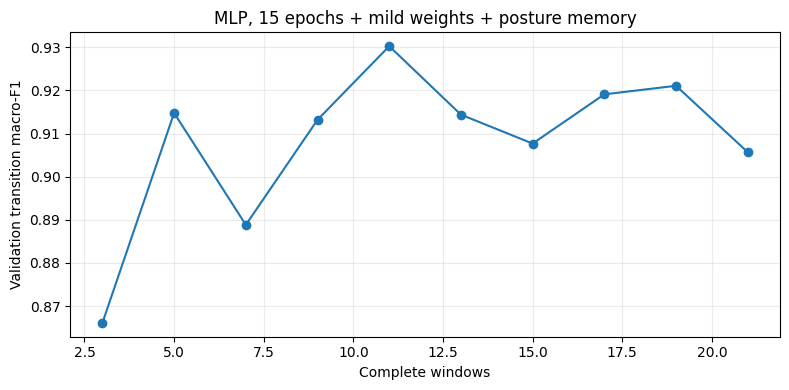

In [7]:
recorded_windows = pd.DataFrame([
    (3, 0.866119, 0.923950), (5, 0.914771, 0.924389),
    (7, 0.888835, 0.934704), (9, 0.913176, 0.937444),
    (11, 0.930245, 0.932897), (13, 0.914375, 0.946619),
    (15, 0.907673, 0.946966), (17, 0.919084, 0.943504),
    (19, 0.921063, 0.952612), (21, 0.905676, 0.944787),
], columns=["window", "transition_f1", "common_f1"])
if RUN_MLP_EXPERIMENTS:
    window_results = {3: condition_results["Three windows + weights"]}
    for window in recorded_windows.window.iloc[1:]:
        window_results[int(window)] = evaluate_mlp_cv(int(window), weight_exponent=0.5)
    window_folds = pd.concat([folds.assign(window=window)
                              for window, folds in window_results.items()], ignore_index=True)
    window_summary = window_folds.groupby("window", as_index=False)[
        ["transition_f1", "common_f1", "elapsed_seconds"]].mean()
    display(window_folds[["window", "fold", "transition_f1", "common_f1"]].round(6))
else:
    window_summary = recorded_windows.copy()
window_summary["features"] = window_summary.window * len(FEATURE_COLUMNS)
display(window_summary.round(6))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(window_summary.window, window_summary.transition_f1, marker="o")
ax.set(xlabel="Complete windows", ylabel="Validation transition macro-F1",
       title="MLP, 15 epochs + mild weights + posture memory")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 4. Earlier MLP tuning and practical window selection

The earlier MLP-specific search compared 19 configurations on the same three participant folds, then checked a shortlist on two more split seeds. It varied context, PCA, common-class caps, weighting, ROS and stopping metric while keeping the network architecture and optimiser fixed. These runs used early stopping, up to 100 epochs, and selected each fold's best epoch; their F1 values are **not directly comparable** with the fixed-15-epoch results above. They support the choice of full three-window raw features, mild weights, posture memory and a 15-epoch final training duration. The lists below transcribe the saved rounded outputs; the original executable search is included after the tables.

In [8]:
recorded_tuning_initial = pd.DataFrame([('current', 0.7821, 0.8113, 0.9222), ('transition_stop', 0.785, 0.8048, 0.9169), ('mild_weights_only', 0.7919, 0.8253, 0.9182), ('all_rows_only', 0.7753, 0.8076, 0.9182), ('no_pca_only', 0.7571, 0.763, 0.9081), ('past2_only', 0.783, 0.7997, 0.9119), ('past3_only', 0.8073, 0.8208, 0.912), ('offline3_only', 0.8473, 0.8593, 0.8989), ('past2_full_raw_mild', 0.8067, 0.8384, 0.9206), ('past3_full_raw_mild', 0.8206, 0.8363, 0.9229), ('offline3_full_raw_mild', 0.8714, 0.9114, 0.9188), ('offline_raw_unweighted', 0.8836, 0.9075, 0.9165), ('offline_raw_inverse', 0.876, 0.913, 0.9222), ('offline_all_pca_mild', 0.863, 0.9054, 0.9208), ('offline_cap_raw_mild', 0.8723, 0.8939, 0.9075), ('offline_ros60', 0.8812, 0.9075, 0.9271), ('offline_ros100', 0.8796, 0.9123, 0.9213), ('past2_raw_unweighted', 0.807, 0.829, 0.9202), ('past2_raw_inverse', 0.8009, 0.7968, 0.9061)],
    columns=["trial", "plain_transition_f1", "memory_transition_f1", "common_f1"])
recorded_tuning_shortlist = pd.DataFrame([('current', 'plain', 0.7518, 0.0348, 0.9162), ('current', 'memory', 0.7835, 0.0404, 0.9162), ('offline_raw_inverse', 'plain', 0.8812, 0.0172, 0.9182), ('offline_raw_inverse', 'memory', 0.9042, 0.0327, 0.9182), ('offline_ros100', 'plain', 0.8874, 0.0181, 0.9179), ('offline_ros100', 'memory', 0.908, 0.0329, 0.9179), ('offline3_full_raw_mild', 'plain', 0.8796, 0.0227, 0.9214), ('offline3_full_raw_mild', 'memory', 0.9084, 0.0331, 0.9214), ('offline_raw_unweighted', 'plain', 0.8802, 0.0245, 0.9191), ('offline_raw_unweighted', 'memory', 0.8986, 0.0312, 0.9191), ('past2_full_raw_mild', 'plain', 0.7989, 0.0181, 0.9231), ('past2_full_raw_mild', 'memory', 0.8309, 0.0296, 0.9231)],
    columns=["trial", "method", "transition_f1", "fold_sd", "common_f1"])
recorded_best_epochs = [10, 15, 6, 19, 22, 25, 29, 8, 12]
recorded_per_class_change = pd.DataFrame([('STAND_TO_SIT', 0.7908, 0.8885, 0.0977), ('SIT_TO_STAND', 0.8768, 0.9818, 0.105), ('SIT_TO_LIE', 0.8905, 0.9505, 0.06), ('LIE_TO_SIT', 0.7027, 0.8723, 0.1696), ('STAND_TO_LIE', 0.834, 0.8965, 0.0625), ('LIE_TO_STAND', 0.6061, 0.8607, 0.2545)],
    columns=["transition", "old_f1", "selected_f1", "change"])
display(recorded_tuning_initial.round(4))
print("Nine-fold shortlist (three split seeds):")
display(recorded_tuning_shortlist.round(4))
print("Selected in the early-stopping study: offline3_full_raw_mild + memory")
print("Best epochs:", recorded_best_epochs, "; median fixed training duration:",
      int(np.median(recorded_best_epochs)))
display(recorded_per_class_change.round(4))

,trial,plain_transition_f1,memory_transition_f1,common_f1
0,current,0.7821,0.8113,0.9222
1,transition_stop,0.7850,0.8048,0.9169
2,mild_weights_only,0.7919,0.8253,0.9182
3,all_rows_only,0.7753,0.8076,0.9182
4,no_pca_only,0.7571,0.7630,0.9081
5,past2_only,0.7830,0.7997,0.9119
6,past3_only,0.8073,0.8208,0.9120
7,offline3_only,0.8473,0.8593,0.8989
8,past2_full_raw_mild,0.8067,0.8384,0.9206
9,past3_full_raw_mild,0.8206,0.8363,0.9229


Nine-fold shortlist (three split seeds):


,trial,method,transition_f1,fold_sd,common_f1
0,current,plain,0.7518,0.0348,0.9162
1,current,memory,0.7835,0.0404,0.9162
2,offline_raw_inverse,plain,0.8812,0.0172,0.9182
3,offline_raw_inverse,memory,0.9042,0.0327,0.9182
4,offline_ros100,plain,0.8874,0.0181,0.9179
5,offline_ros100,memory,0.9080,0.0329,0.9179
6,offline3_full_raw_mild,plain,0.8796,0.0227,0.9214
7,offline3_full_raw_mild,memory,0.9084,0.0331,0.9214
8,offline_raw_unweighted,plain,0.8802,0.0245,0.9191
9,offline_raw_unweighted,memory,0.8986,0.0312,0.9191


Selected in the early-stopping study: offline3_full_raw_mild + memory
Best epochs: [10, 15, 6, 19, 22, 25, 29, 8, 12] ; median fixed training duration: 15


,transition,old_f1,selected_f1,change
0,STAND_TO_SIT,0.7908,0.8885,0.0977
1,SIT_TO_STAND,0.8768,0.9818,0.1050
2,SIT_TO_LIE,0.8905,0.9505,0.0600
3,LIE_TO_SIT,0.7027,0.8723,0.1696
4,STAND_TO_LIE,0.8340,0.8965,0.0625
5,LIE_TO_STAND,0.6061,0.8607,0.2545


The later fixed-15-epoch context sweep selects window length separately. Following the shared notebook, choose the shortest tested length within 0.005 transition F1 of the measured peak, provided common-class F1 is no more than 0.01 below the three-window reference. The posture-memory rule remains fixed. This is a practical near-peak choice, not proof of a universal optimum or statistical plateau.

In [9]:
peak = window_summary.transition_f1.max()
common_three = window_summary.loc[window_summary.window == 3, "common_f1"].iat[0]
eligible = window_summary[(peak - window_summary.transition_f1 <= 0.005) &
                          (window_summary.common_f1 >= common_three - 0.01)]
selected_window = int(eligible.window.min())
chosen = window_summary.loc[window_summary.window == selected_window].iloc[0]
selection = pd.DataFrame([{"window": selected_window,
                           "transition_f1": chosen.transition_f1,
                           "common_f1": chosen.common_f1,
                           "measured_peak": peak,
                           "longer_lengths_checked": int((window_summary.window > selected_window).sum())}])
display(selection.round(6))
if not RUN_MLP_EXPERIMENTS:
    assert selected_window == 11

,window,transition_f1,common_f1,measured_peak,longer_lengths_checked
0,11,0.930245,0.932897,0.930245,5


### Optional full early-stopping search

This code reproduces the historical 19-configuration search and its nine-fold shortlist. It reads training participants only. It is off by default because it trains many networks; the recorded tables above remain visible without running it.

In [10]:
def run_mlp_tuning():
    from copy import deepcopy
    import torch
    import torch.nn.functional as F
    from torch import nn
    from torch.utils.data import DataLoader, TensorDataset
    X, y, subject = x_train, y_train - 1, groups_train
    names = train_df[["activity_id", "activity_label"]].drop_duplicates().sort_values("activity_id").activity_label.tolist()
    LEARNING_RATE = 0.001
    WEIGHT_DECAY = 0.0001
    BATCH_SIZE = 128
    MAX_EPOCHS = 100
    PATIENCE = 12
    ALLOW_NEXT_WINDOW = True
    views = {}
    rows = np.arange(len(X))
    for name, offsets in [('single', [0]), ('past2', [-1, 0]),
                          ('past3', [-2, -1, 0]), ('offline3', [-1, 0, 1])]:
        blocks = []
        for offset in offsets:
            neighbor = np.clip(rows + offset, 0, len(X) - 1)
            boundary = subject[neighbor] != subject
            neighbor[boundary] = rows[boundary]
            blocks.append(X[neighbor])
        views[name] = np.hstack(blocks)
    print('Input dimensions:', {name: values.shape[1] for name, values in views.items()})


    def make_model(inputs):
        model = nn.Sequential(
            nn.Linear(inputs, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 12),
        )
        for layer in model:
            if isinstance(layer, nn.Linear):
                if layer.out_features == 12:
                    nn.init.xavier_uniform_(layer.weight)
                else:
                    nn.init.kaiming_normal_(layer.weight, nonlinearity='relu')
                nn.init.zeros_(layer.bias)
        return model


    def memory_predictions(probabilities, people):
        prediction = probabilities.argmax(axis=1)
        gate = np.isin(prediction, [8, 10])
        mass = probabilities[:, [8, 10]].sum(axis=1)
        score = np.divide(probabilities[:, 10], mass, out=np.full(len(people), 0.5), where=mass > 0)
        start = 0
        for row in range(len(people)):
            if row == 0 or people[row] != people[row - 1]:
                start = row
            past = probabilities[max(start, row - 8):row, [3, 4]].sum(axis=0)
            if past.sum() >= 0.75:
                score[row] = past[1] / past.sum()
        prediction[gate] = np.where(score[gate] > 0.5, 10, 8)
        return prediction


    def fit_fold(config, tr, va, fold, split_seed):
        name, context, components, limit, exponent, ros, stopping = config
        seed = split_seed + fold
        features = views[context]
        rng = np.random.default_rng(seed)
        selected = []
        for activity in range(12):
            rows = np.flatnonzero(y[tr] == activity)
            if activity < 6 and limit and len(rows) > limit:
                rows = rng.choice(rows, limit, replace=False)
            selected.extend(rows)
        sampled = tr[np.sort(selected)]
        counts = np.bincount(y[sampled], minlength=12)
        weights = torch.tensor((len(sampled) / (12 * counts)) ** exponent, dtype=torch.float32)
        if ros:
            extra = []
            for activity in range(6, 12):
                found = sampled[y[sampled] == activity]
                if len(found) < ros:
                    extra.extend(rng.choice(found, ros - len(found), replace=True))
            sampled = np.concatenate((sampled, np.asarray(extra, dtype=int)))
        scaler = StandardScaler()
        train_x = scaler.fit_transform(features[sampled]).astype(np.float32)
        val_x = scaler.transform(features[va]).astype(np.float32)
        if components:
            pca = PCA(n_components=components, svd_solver='randomized', random_state=seed)
            train_x = pca.fit_transform(train_x).astype(np.float32)
            val_x = pca.transform(val_x).astype(np.float32)
        train_y = y[sampled]
        tx, ty, vx = torch.from_numpy(train_x), torch.from_numpy(train_y), torch.from_numpy(val_x)
        vy = torch.from_numpy(y[va])
        torch.manual_seed(seed)
        model = make_model(train_x.shape[1])
        optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
        loader = DataLoader(TensorDataset(tx, ty), batch_size=BATCH_SIZE, shuffle=True,
                            generator=torch.Generator().manual_seed(seed))
        best_score = -1.0
        best_epoch = 0
        history = []
        for epoch in range(1, MAX_EPOCHS + 1):
            model.train()
            for bx, by in loader:
                optimizer.zero_grad()
                logits = model(bx)
                losses = F.cross_entropy(logits, by, reduction='none')
                loss = (losses * weights[by]).sum() / weights[by].sum()
                loss.backward()
                optimizer.step()
            model.eval()
            with torch.no_grad():
                train_logits = model(tx)
                losses = F.cross_entropy(train_logits, ty, reduction='none')
                train_loss = (losses * weights[ty]).sum() / weights[ty].sum()
                val_logits = model(vx)
                losses = F.cross_entropy(val_logits, vy, reduction='none')
                val_loss = (losses * weights[vy]).sum() / weights[vy].sum()
                f = precision_recall_fscore_support(y[va], val_logits.argmax(1).numpy(), labels=range(12), zero_division=0)[2]
            score = float(f.mean() if stopping == 'all' else f[6:].mean())
            history.append({'epoch': epoch, 'train_loss': train_loss.item(), 'validation_loss': val_loss.item(),
                            'transition_f1': float(f[6:].mean()), 'macro_f1': float(f.mean())})
            if score > best_score + 1e-6:
                best_score, best_epoch = score, epoch
                best_weights = deepcopy(model.state_dict())
            if epoch - best_epoch >= PATIENCE:
                break
        model.load_state_dict(best_weights)
        model.eval()
        with torch.no_grad():
            probabilities = model(vx).softmax(1).numpy()
        result = {'config': config, 'split_seed': split_seed, 'fold': fold,
                  'best_epoch': best_epoch, 'stop_epoch': epoch, 'history': history}
        for method, prediction in [('plain', probabilities.argmax(1)),
                                   ('memory', memory_predictions(probabilities, subject[va]))]:
            p, r, f, n = precision_recall_fscore_support(
                y[va], prediction, labels=range(12), zero_division=0)
            result[method] = {'transition_f1': float(f[6:].mean()),
                              'common_f1': float(f[:6].mean()), 'macro_f1': float(f.mean()),
                              'accuracy': float(np.mean(y[va] == prediction)),
                              'transition_recall': float(r[6:].mean()),
                              'class_f1': f.tolist(), 'class_recall': r.tolist()}
        return result


    trials = [
        ('current', 'single', 200, 300, 1.0, 0, 'all'),
        ('transition_stop', 'single', 200, 300, 1.0, 0, 'transition'),
        ('mild_weights_only', 'single', 200, 300, 0.5, 0, 'transition'),
        ('all_rows_only', 'single', 200, 0, 1.0, 0, 'transition'),
        ('no_pca_only', 'single', 0, 300, 1.0, 0, 'transition'),
        ('past2_only', 'past2', 200, 300, 1.0, 0, 'transition'),
        ('past3_only', 'past3', 200, 300, 1.0, 0, 'transition'),
        ('offline3_only', 'offline3', 200, 300, 1.0, 0, 'transition'),
        ('past2_full_raw_mild', 'past2', 0, 0, 0.5, 0, 'transition'),
        ('past3_full_raw_mild', 'past3', 0, 0, 0.5, 0, 'transition'),
        ('offline3_full_raw_mild', 'offline3', 0, 0, 0.5, 0, 'transition'),
        ('offline_raw_unweighted', 'offline3', 0, 0, 0.0, 0, 'transition'),
        ('offline_raw_inverse', 'offline3', 0, 0, 1.0, 0, 'transition'),
        ('offline_all_pca_mild', 'offline3', 200, 0, 0.5, 0, 'transition'),
        ('offline_cap_raw_mild', 'offline3', 0, 300, 0.5, 0, 'transition'),
        ('offline_ros60', 'offline3', 0, 0, 0.5, 60, 'transition'),
        ('offline_ros100', 'offline3', 0, 0, 0.5, 100, 'transition'),
        ('past2_raw_unweighted', 'past2', 0, 0, 0.0, 0, 'transition'),
        ('past2_raw_inverse', 'past2', 0, 0, 1.0, 0, 'transition'),
    ]


    results = []
    folds = list(StratifiedGroupKFold(3, shuffle=True, random_state=42).split(X, y, subject))
    for trial in trials:
        for fold, (tr, va) in enumerate(folds, 1):
            result = fit_fold(trial, tr, va, fold, split_seed=42)
            results.append(result)
            print(f'{trial[0]}, fold {fold}: NN={result["plain"]["transition_f1"]:.4f}, '
                  f'+memory={result["memory"]["transition_f1"]:.4f}, epoch={result["best_epoch"]}')


    print(f'{"Trial":27} {"NN transition F1":>17} {"+memory F1":>12} {"Common F1":>11}')
    for trial in trials:
        group = [r for r in results if r['config'][0] == trial[0]]
        plain = np.mean([r['plain']['transition_f1'] for r in group])
        memory_score = np.mean([r['memory']['transition_f1'] for r in group])
        common = np.mean([r['memory']['common_f1'] for r in group])
        print(f'{trial[0]:27} {plain:17.4f} {memory_score:12.4f} {common:11.4f}')


    ranked = []
    for trial in trials:
        group = [r for r in results if r['config'][0] == trial[0]]
        score = max(np.mean([r[method]['transition_f1'] for r in group])
                    for method in ['plain', 'memory'])
        ranked.append((score, trial))
    ranked.sort(key=lambda item: item[0], reverse=True)
    offline = [trial for score, trial in ranked if trial[1] == 'offline3'][:4]
    past_only = [trial for score, trial in ranked if trial[1] != 'offline3' and trial[0] != 'current'][:1]
    shortlist = [trials[0]] + offline + past_only

    for trial in shortlist:
        for split_seed in [123, 2026]:
            folds = list(StratifiedGroupKFold(3, shuffle=True, random_state=split_seed).split(X, y, subject))
            for fold, (tr, va) in enumerate(folds, 1):
                result = fit_fold(trial, tr, va, fold, split_seed)
                results.append(result)
                print(f'{trial[0]}, seed {split_seed}, fold {fold}: '
                      f'+memory F1={result["memory"]["transition_f1"]:.4f}, epoch={result["best_epoch"]}')


    reference = [r for r in results if r['config'][0] == 'current']
    minimum_common = np.mean([r['memory']['common_f1'] for r in reference]) - 0.01
    choices = []
    print(f'{"Shortlist":27} {"Method":>8} {"Transition F1":>14} {"Fold SD":>9} {"Common F1":>11}')
    for trial in shortlist:
        group = [r for r in results if r['config'][0] == trial[0]]
        for method in ['plain', 'memory']:
            values = [r[method]['transition_f1'] for r in group]
            mean = float(np.mean(values))
            common = float(np.mean([r[method]['common_f1'] for r in group]))
            print(f'{trial[0]:27} {method:>8} {mean:14.4f} {np.std(values, ddof=1):9.4f} {common:11.4f}')
            if common >= minimum_common and (ALLOW_NEXT_WINDOW or trial[1] != 'offline3'):
                choices.append((mean, trial, method))
    best_score, best_trial, best_method = max(choices, key=lambda item: item[0])
    chosen = [r for r in results if r['config'][0] == best_trial[0]]
    final_epochs = int(np.median([r['best_epoch'] for r in chosen]))
    print('\nSelected:', best_trial[0], '| Method:', best_method)
    print('Best epochs:', [r['best_epoch'] for r in chosen], '| Final duration:', final_epochs)


    fig, axes = plt.subplots(2, 3, figsize=(14, 7))
    for column, result in enumerate([r for r in chosen if r['split_seed'] == 42]):
        history = result['history']
        epochs = [row['epoch'] for row in history]
        axes[0, column].plot(epochs, [row['train_loss'] for row in history], label='Training')
        axes[0, column].plot(epochs, [row['validation_loss'] for row in history], label='Validation')
        axes[0, column].axvline(result['best_epoch'], color='green', linestyle='--')
        axes[0, column].set(title=f'Fold {column + 1}', xlabel='Epoch', ylabel='Weighted loss')
        axes[0, column].legend()
        axes[1, column].plot(epochs, [row['transition_f1'] for row in history])
        axes[1, column].axvline(result['best_epoch'], color='green', linestyle='--')
        axes[1, column].set(xlabel='Epoch', ylabel='Validation transition F1')
    fig.tight_layout()
    plt.show()


    old_f1 = np.mean([r['memory']['class_f1'] for r in reference], axis=0)
    new_f1 = np.mean([r[best_method]['class_f1'] for r in chosen], axis=0)
    print(f'{"Transition":22} {"Previous F1":>12} {"Selected F1":>12} {"Change":>9}')
    for activity in range(6, 12):
        print(f'{names[activity]:22} {old_f1[activity]:12.4f} {new_f1[activity]:12.4f}'
              f' {new_f1[activity] - old_f1[activity]:+9.4f}')

    return best_trial, best_method, final_epochs, results

if RUN_MLP_TUNING:
    mlp_selection = run_mlp_tuning()

## 5. PCA quality and runtime comparison

At the selected eleven-window input (6,171 features), compare raw features with PCA-200 and PCA-500 on the same three folds, keeping 15 epochs, mild weights, memory and no ROS fixed. Timing includes scaling, PCA where used, fitting and prediction; it excludes CSV loading and shared context construction. A useful PCA option must lose no more than 0.005 in both transition and common F1 and run faster in two timing comparisons. Times depend on the machine and workload.

In [11]:
recorded_pca = pd.DataFrame([
    ("raw", 0.930245, 0.932897, 20.8650),
    ("pca200", 0.920188, 0.937842, 9.7350),
    ("pca500", 0.947498, 0.956694, 18.8957),
], columns=["representation", "transition_f1", "common_f1", "mean_seconds_per_fold"])
recorded_paired_timing = pd.DataFrame([
    (1, "raw", 20.8650), (1, "pca500", 18.8957),
    (2, "raw", 16.5424), (2, "pca500", 19.0061),
], columns=["run", "representation", "mean_seconds_per_fold"])
if RUN_MLP_PCA:
    pca_runs = []
    for representation in ["raw", "pca200", "pca500"]:
        folds = evaluate_mlp_cv(selected_window, weight_exponent=0.5,
                                representation=representation)
        pca_runs.append({"representation": representation,
                         "transition_f1": folds.transition_f1.mean(),
                         "common_f1": folds.common_f1.mean(),
                         "mean_seconds_per_fold": folds.elapsed_seconds.mean()})
    pca_summary = pd.DataFrame(pca_runs)
    paired_timing = pd.DataFrame([
        (1, row.representation, row.mean_seconds_per_fold)
        for row in pca_summary.itertuples()
        if row.representation in ("raw", "pca500")],
        columns=recorded_paired_timing.columns)
    # Reverse order in the second timing comparison.
    for representation in ["pca500", "raw"]:
        folds = evaluate_mlp_cv(selected_window, weight_exponent=0.5,
                                representation=representation)
        paired_timing.loc[len(paired_timing)] = (2, representation,
                                                 folds.elapsed_seconds.mean())
else:
    pca_summary = recorded_pca.copy()
    paired_timing = recorded_paired_timing.copy()
raw = pca_summary.loc[pca_summary.representation == "raw"].iloc[0]
pca_summary["transition_change"] = pca_summary.transition_f1 - raw.transition_f1
pca_summary["common_change"] = pca_summary.common_f1 - raw.common_f1
pca_summary["time_saved_pct"] = 100 * (1 - pca_summary.mean_seconds_per_fold /
                                       raw.mean_seconds_per_fold)
display(pca_summary.round(6))
paired = paired_timing.pivot(index="run", columns="representation", values="mean_seconds_per_fold")
paired["pca500_time_saved_pct"] = 100 * (1 - paired.pca500 / paired.raw)
display(paired.round(4))
selected_representation = "raw"  # The recorded second timing run did not support PCA-500.

,representation,transition_f1,common_f1,mean_seconds_per_fold,transition_change,common_change,time_saved_pct
0,raw,0.930245,0.932897,20.8650,0.000000,0.000000,0.000000
1,pca200,0.920188,0.937842,9.7350,-0.010057,0.004945,53.342919
2,pca500,0.947498,0.956694,18.8957,0.017253,0.023797,9.438294


representation,pca500,raw,pca500_time_saved_pct
run,,,
1,18.8957,20.8650,9.4383
2,19.0061,16.5424,-14.8932


PCA-200 saves time but reduces transition F1 by about 0.010, exceeding the quality tolerance. PCA-500 improves both F1 measures in the recorded three-fold comparison, but the second paired timing makes it slower than raw features. The retained eleven-window MLP therefore uses raw features. This does not imply that PCA-500 is predictively harmful; its measured speed benefit is not repeatable here.

## 6. Fixed MLP configurations: descriptive test comparison

The first two rows below are single-window and unweighted three-window checks with the same 15-epoch network and posture memory. The selected row uses eleven raw windows, mild weights, memory and no ROS. Window length and representation were chosen using training-participant validation; test results did not choose them. The official test participants were inspected during earlier development, so these scores are descriptive rather than untouched final estimates.

The recorded selected-pipeline predictions below were reproduced using the shared implementation and match the main notebook's final MLP row. Set `RUN_MLP_TEST=True` to refit all three configurations. The saved predictions let the per-class and error analysis run without refitting.

In [12]:
test_df = pd.read_csv(ROOT / "our approach/wrangled data/hapt_test.csv")
assert list(test_df.columns) == list(train_df.columns)
x_test, y_test, groups_test = arrays(test_df)
assert x_test.shape == (3162, 561)
assert len(np.unique(groups_test)) == 9
assert set(groups_train).isdisjoint(groups_test)
assert len(np.unique(groups_test)) == 1 + np.count_nonzero(groups_test[1:] != groups_test[:-1])
RECORDED_TEST_HASHES = {
    "features": "af0410255bc1e58741708b662229095d88a98a972df9821e7072b7831e0e7b40",
    "labels": "0dc809d336c3a639518eab7d63d005145074b2c08d7175b54dc2435dc36eb7f4",
    "participants": "9dd9d09667c9dd0477db3d3514a4b2688a1352a808a73060b760309f840d62e5",
}
for name, values in [("features", x_test), ("labels", y_test),
                     ("participants", groups_test)]:
    digest = hashlib.sha256(np.ascontiguousarray(values).tobytes()).hexdigest()
    assert digest == RECORDED_TEST_HASHES[name], "Test data differ from the saved predictions."
recorded_test_summary = pd.DataFrame([('single', 0.8607087849841889, 0.8520520994226999, 0.947728534594582, 0.9042186597893854, 0.9443390259329538), ('three', 0.9251362767329153, 0.9019664012948175, 0.9605801805925679, 0.9428582286627417, 0.9585705249841873), ('selected', 0.9716163278240942, 0.9552172817597248, 0.9766203523913477, 0.9741183401077212, 0.9756483238456674)],
    columns=["pipeline", "transition_f1", "transition_recall", "common_f1", "macro_f1", "accuracy"])
recorded_selected_predictions = np.fromstring("""
5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 7 4 4 4 4 4 4 4 4 4 4 4 4 4 8 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 11 11 11 11 6 6
6 6 6 6 6 6 6 6 6 6 10 10 4 4 4 4 4 4 4 4 4 4 4 4 9 9 6 6 6 6 6 6 6 6 6 6 6 6 6 12 1 1 1 1 1 1 1 1 1 1 1 1 1 1
1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 3 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 3 3 3 3 3
3 3 2 2 2 2 2 2 2 2 5 5 5 5 5 5 5 5 5 5 5 7 4 4 4 4 4 4 4 4 4 4 4 8 5 5 5 5 5 5 5 5 5 5 5 5 11 11 6 6 6 6 6 6
6 6 6 6 6 10 4 4 4 4 4 4 4 4 4 4 4 9 6 6 6 6 6 6 6 6 6 6 6 6 6 6 12 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
1 1 1 1 1 1 1 1 3 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 2 2 2 2 2 2 2 5
5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 7 7 4 4 4 4 4 4 4 4 4 4 4 4 8 5 5 5 5 5 5 5 5 5 5 5 5 5 11 11 11 11 6 6 6 6 6 6
6 6 6 6 6 6 6 6 6 10 10 4 4 4 4 4 4 4 4 4 4 4 4 9 9 6 6 6 6 6 6 6 6 6 6 6 6 6 6 12 1 1 1 1 1 1 1 1 1 1 1 1 1 1
1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 3 3 3 3 3 2 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 2 3 3 3
3 3 3 3 3 3 2 2 2 2 2 2 2 2 5 5 5 5 5 5 5 5 5 5 5 5 5 5 7 4 4 4 4 4 4 4 4 4 4 4 4 4 4 8 5 5 5 5 5 5 5 5 5 5 5
5 11 11 11 6 6 6 6 6 6 6 6 6 6 6 10 10 4 4 4 4 4 4 4 4 4 4 4 9 9 6 6 6 6 6 6 6 6 6 6 6 6 12 1 1 1 1 1 1 1 1 1
1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 3 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 3 3 3 3
3 3 3 2 2 2 2 2 2 2 2 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 5 5 5 4 4 4 4 5 5 5 5 5 5 11 6 6 6 6 6 6 6 6
6 6 6 6 10 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 9 9 6 6 6 6 6 6 6 6 6 6 6 6 12 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
1 1 1 1 1 1 1 1 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 2 1 3 3 3 3 3 3 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2
5 5 5 5 5 5 5 5 5 5 5 7 4 4 4 4 4 4 4 4 4 4 4 4 4 5 5 5 5 5 5 5 5 5 5 5 5 5 11 11 11 6 6 6 6 6 6 6 6 6 6 6 6 6
10 4 4 4 4 4 4 4 4 4 4 4 4 4 4 9 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 12 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
1 1 1 1 1 1 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 2 2 2 2 2 2 2 5 5 5 5 5
5 5 5 5 5 5 5 7 4 4 4 4 4 4 4 4 4 4 4 4 5 5 5 5 5 5 5 5 5 5 5 5 11 11 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 10 4 4 4 4
4 4 4 4 4 4 5 4 9 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 3 3 3 3
3 3 2 2 2 2 2 2 2 3 3 3 3 3 3 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 4
5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 11 11 6 6 6 6 6 6 6 6 6 6 10 4 4 4 4 4 4 4 4 4 4 5 5 5 9 6 6 6 6 6
6 6 6 6 6 6 6 6 6 6 6 6 6 12 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 3 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 3
3 3 3 3 3 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 5 5 5 5 5 5 5 5 5 5 5 7 4 4 4 4 4 4 4 4 4 4 4 4 5 5 5
5 5 5 5 5 5 5 5 5 5 5 5 5 11 11 6 6 6 6 6 6 6 6 6 6 6 6 6 6 10 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 5 4 9 6 6 6 6 6 6
6 6 6 6 6 6 6 12 12 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 3 3 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 2
3 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 2 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5
5 5 7 4 4 4 4 4 4 4 4 4 5 8 5 5 5 5 5 5 5 5 5 5 5 5 11 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 10 4 4 4 4 4 4 4
5 4 4 5 5 4 4 4 4 4 9 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 12 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 3 3 3 3 3 3
3 3 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 2 5 5 5 5 5 5 5 5 5 5 5 5 5 5
5 5 7 4 4 4 4 4 4 4 4 4 4 4 4 4 8 5 5 5 5 5 5 5 5 5 5 5 5 5 5 11 11 6 6 6 6 6 6 6 6 6 6 6 6 6 10 4 4 4 4 4 4 4
4 4 4 4 9 9 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 12 12 12 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
1 1 1 1 1 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 2 2 2 2
2 2 2 2 2 2 5 5 5 5 5 5 5 5 5 5 5 5 5 7 7 4 4 4 4 4 4 4 4 4 4 8 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 4 11 6 6 6 6 6
6 6 6 6 6 6 6 6 6 10 10 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 9 9 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 12 12 1 1 1 1 1 1 1 1
1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 3 3 3 3 3 3
2 2 2 2 2 2 2 2 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 7 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 8 5 5 5 5 5 5
5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 11 11 11 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 10 10 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4
4 4 9 9 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 12 12 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
1 3 3 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2
2 2 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 7 7 4 4 4 4 4 4 4 4 4 4 4 4 4 8 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 11
11 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 10 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 9 9 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6
12 12 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 3 3 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3
3 3 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 2 2 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 4 4 4 4 7
4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 8 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 11 11 11 11 6 6 6 6 6 6 6 6 6 6 6
6 6 6 6 6 6 6 10 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 9 9 9 6 6 6 6 6 6 6 6 6 6 6 6 6 6 12 1 1 1 1 1 1 1 1 1 1 1 1
1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3
2 2 2 2 2 2 2 2 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 7 7 4 4 5 4 4 4 4 5 5 5 4 5 5 5 5 5 5 5 5 5 5 5 5 5
5 5 5 5 5 5 5 5 11 11 11 11 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 10 10 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 9 9
9 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 12 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 3 3 3 3 3 3 3 3 3 3 2 2 2 2
2 2 2 2 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 7
4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 11 11 5 11 11 11 6 6 6 6 6 6 6 6 6 6
6 6 6 6 6 6 6 6 10 10 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 9 9 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 12 12 12 1 1 1
1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 2 2 2
2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 2 2 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 7 4 4 4 4 4 4 4 4
4 4 4 4 4 4 4 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 11 11 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 10 4 4 4 4 4 4 4 4 4
4 4 4 4 4 4 4 4 4 4 4 9 9 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 12 12 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
1 1 1 1 1 1 1 1 1 3 3 3 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3
3 3 2 2 2 2 2 2 2 2 2 2
""", sep=" ", dtype=np.int64)
assert len(recorded_selected_predictions) == len(y_test)
if RUN_MLP_TEST:
    test_rows = []
    for name, context, weight in [("single", "single", 0),
                                  ("three", "bidirectional", 0),
                                  ("selected", selected_window, 0.5)]:
        result = fit_mlp_test(context, weight, selected_representation)
        if name == "selected":
            selected_test_predictions = result["predictions"]
        test_rows.append({"pipeline": name,
                          **{key: result[key] for key in
                             ["transition_f1", "transition_recall", "common_f1",
                              "macro_f1", "accuracy"]}})
    test_summary = pd.DataFrame(test_rows)
else:
    selected_test_predictions = recorded_selected_predictions.copy()
    test_summary = recorded_test_summary.copy()
selected_test_score = scores(y_test, selected_test_predictions)
if not RUN_MLP_TEST:
    recorded_selected = recorded_test_summary.set_index("pipeline").loc["selected"]
    for metric in ["transition_f1", "transition_recall", "common_f1", "macro_f1", "accuracy"]:
        np.testing.assert_allclose(selected_test_score[metric], recorded_selected[metric], atol=1e-12)
display(test_summary.round(6))

,pipeline,transition_f1,transition_recall,common_f1,macro_f1,accuracy
0,single,0.860709,0.852052,0.947729,0.904219,0.944339
1,three,0.925136,0.901966,0.960580,0.942858,0.958571
2,selected,0.971616,0.955217,0.976620,0.974118,0.975648


### Selected MLP: per-class test recall

Recall is the number of correct test windows divided by support for that class. The table and transition metrics below are computed from the saved selected-pipeline predictions, not copied from the summary table.

In [13]:
activity_names = test_df[["activity_id", "activity_label"]].drop_duplicates().set_index(
    "activity_id").activity_label
mlp_test_class_recall = pd.DataFrame({
    "activity_id": LABELS,
    "activity": activity_names.reindex(LABELS).to_numpy(),
    "support": selected_test_score["support"],
    "correct": [int(np.count_nonzero((y_test == label) &
                                     (selected_test_predictions == label))) for label in LABELS],
    "recall": selected_test_score["per_class_recall"],
})
np.testing.assert_allclose(mlp_test_class_recall.correct / mlp_test_class_recall.support,
                           mlp_test_class_recall.recall, rtol=0, atol=1e-15)
display(mlp_test_class_recall.round(6))

,activity_id,activity,support,correct,recall
0,1,WALKING,496,491,0.989919
1,2,WALKING_UPSTAIRS,471,467,0.991507
2,3,WALKING_DOWNSTAIRS,420,415,0.988095
3,4,SITTING,508,475,0.935039
4,5,STANDING,556,535,0.962230
5,6,LAYING,545,544,0.998165
6,7,STAND_TO_SIT,23,20,0.869565
7,8,SIT_TO_STAND,10,10,1.000000
8,9,SIT_TO_LIE,32,32,1.000000
9,10,LIE_TO_SIT,25,24,0.960000


### MLP transition metrics, confusion and individual errors

Precision includes false positives from every test class. The error table includes all misclassified rows whose true or predicted activity is a transition; `test_row` is the zero-based CSV row position, not a timestamp. The adjacent true labels are shown only for post-hoc diagnosis, never as model inputs.

In [14]:
from sklearn.metrics import confusion_matrix
mlp_test_confusion = confusion_matrix(y_test, selected_test_predictions, labels=LABELS)
mlp_transition_metrics = pd.DataFrame({
    "activity_id": LABELS,
    "activity": activity_names.reindex(LABELS).to_numpy(),
    "support": selected_test_score["support"],
    "precision": selected_test_score["per_class_precision"],
    "recall": selected_test_score["per_class_recall"],
    "f1": selected_test_score["per_class_f1"],
}).loc[lambda frame: frame.activity_id >= 7].reset_index(drop=True)
wrong = np.flatnonzero(y_test != selected_test_predictions)
mlp_all_test_errors = pd.DataFrame({
    "test_row": wrong, "participant": groups_test[wrong],
    "actual_id": y_test[wrong], "predicted_id": selected_test_predictions[wrong],
})
mlp_all_test_errors["actual"] = mlp_all_test_errors.actual_id.map(activity_names)
mlp_all_test_errors["predicted"] = mlp_all_test_errors.predicted_id.map(activity_names)
mlp_transition_cases = mlp_all_test_errors.loc[
    (mlp_all_test_errors.actual_id >= 7) |
    (mlp_all_test_errors.predicted_id >= 7)].copy()
mlp_transition_cases["previous_actual"] = [
    activity_names[y_test[row - 1]] if row > 0 and groups_test[row - 1] == groups_test[row]
    else "Participant boundary" for row in mlp_transition_cases.test_row]
mlp_transition_cases["next_actual"] = [
    activity_names[y_test[row + 1]] if row + 1 < len(y_test) and groups_test[row + 1] == groups_test[row]
    else "Participant boundary" for row in mlp_transition_cases.test_row]
mlp_error_counts = {
    "total_errors": len(wrong),
    "transition_support": int(np.count_nonzero(y_test >= 7)),
    "correct_transitions": int(np.count_nonzero((y_test >= 7) &
                                                (y_test == selected_test_predictions))),
    "true_transition_errors": int(np.count_nonzero((y_test >= 7) &
                                                   (y_test != selected_test_predictions))),
    "common_to_transition": int(np.count_nonzero((y_test <= 6) &
                                                 (selected_test_predictions >= 7))),
}
display(mlp_transition_metrics.round(4))
display(mlp_transition_cases.reset_index(drop=True))
display(pd.Series(mlp_error_counts, name="windows").to_frame())

,activity_id,activity,support,precision,recall,f1
0,7,STAND_TO_SIT,23,1.0000,0.8696,0.9302
1,8,SIT_TO_STAND,10,1.0000,1.0000,1.0000
2,9,SIT_TO_LIE,32,1.0000,1.0000,1.0000
3,10,LIE_TO_SIT,25,0.9600,0.9600,0.9600
4,11,STAND_TO_LIE,49,0.9787,0.9388,0.9583
5,12,LIE_TO_STAND,27,1.0000,0.9630,0.9811


,test_row,participant,actual_id,predicted_id,actual,predicted,previous_actual,next_actual
0,51,2,11,6,STAND_TO_LIE,LAYING,STAND_TO_LIE,LAYING
1,65,2,10,4,LIE_TO_SIT,SITTING,LIE_TO_SIT,SITTING
2,1163,10,6,11,LAYING,STAND_TO_LIE,STAND_TO_LIE,LAYING
3,1174,10,4,10,SITTING,LIE_TO_SIT,LAYING,SITTING
4,1988,18,7,4,STAND_TO_SIT,SITTING,STAND_TO_SIT,STAND_TO_SIT
5,1989,18,7,4,STAND_TO_SIT,SITTING,STAND_TO_SIT,SITTING
6,2390,20,7,4,STAND_TO_SIT,SITTING,STANDING,STAND_TO_SIT
7,2434,20,11,6,STAND_TO_LIE,LAYING,STAND_TO_LIE,LAYING
8,2810,24,11,5,STAND_TO_LIE,STANDING,STAND_TO_LIE,STAND_TO_LIE
9,2874,24,12,1,LIE_TO_STAND,WALKING,LIE_TO_STAND,WALKING


,windows
total_errors,77
transition_support,166
correct_transitions,158
true_transition_errors,8
common_to_transition,2


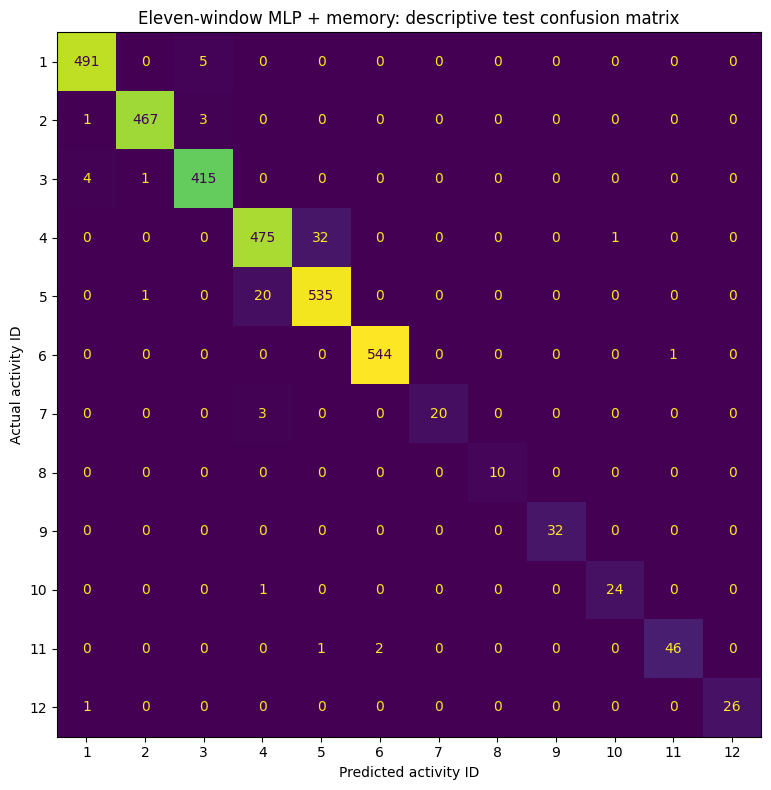

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(mlp_test_confusion, display_labels=LABELS).plot(
    ax=ax, colorbar=False, values_format="d")
ax.set(title="Eleven-window MLP + memory: descriptive test confusion matrix",
       xlabel="Predicted activity ID", ylabel="Actual activity ID")
plt.tight_layout()
plt.show()

#### Interpretation and limits

The selected MLP correctly labels 158 of 166 true transition windows. STAND_TO_SIT has the lowest transition recall (20/23, or 86.96%); SIT_TO_STAND and SIT_TO_LIE are perfect in this small test sample (10 and 32 windows). The memory rule can only switch SIT_TO_LIE and STAND_TO_LIE predictions. It cannot repair predictions outside that pair. Individual errors motivate inspection of raw sensor recordings, but the prepared CSV lacks exact timestamps and within-participant recording IDs, so these rows alone do not establish a physical cause.

The initial early-stopping search, later fixed-epoch context sweep, and final test refit are distinct stages. The eleven-window final model uses future features and is not an immediate online predictor. The test split was previously viewed during development, so the reported test values remain descriptive.